# CoEVFold - GREMLIN Publication Benchmark

Runs the coupling-inference stage of CoEVFold **once, automatically, back-to-back**, across a
fixed panel of 20 small published heteromer complexes, using the **GREMLIN backend exactly as
in the original notebook** (unmodified MRF fitting, 100 iterations, `lam_w=0.01`).

For each complex this records:
- **Runtime**: MSA-generation time, GREMLIN fit time, total wall-clock time per complex
- **Resources**: peak RAM, peak CPU%, peak GPU utilization / GPU memory
- **Accuracy**: intermolecular (inter-chain) Top-L/5 precision against the real PDB structure

Everything is written to `gremlin_publication_results.csv` plus summary plots at the end, to use
as the GREMLIN baseline when comparing against the CCMpred version of this same notebook.

No uploads needed - each complex is fetched directly from the RCSB by its PDB ID. Just
**Runtime -> Run all**.


In [ ]:
#@title Setup - ColabDesign + HHsuite + MSA tools (no AlphaFold params needed for a coupling-only benchmark)
unified_memory = True  #@param {type:"boolean"}
import os, sys, time, gc, re, json, subprocess, threading
if unified_memory:
    for k, v in {"TF_FORCE_UNIFIED_MEMORY": "1", "XLA_PYTHON_CLIENT_MEM_FRACTION": "4.0"}.items():
        os.environ[k] = v

if not os.path.isdir("colabdesign"):
    print("installing ColabDesign")
    os.system("pip -q install git+https://github.com/sokrypton/ColabDesign.git@gamma")
    os.system("ln -s /usr/local/lib/python3.*/dist-packages/colabdesign colabdesign")
    os.system("wget -q https://raw.githubusercontent.com/sokrypton/ColabFold/main/colabfold/colabfold.py -O colabfold_utils.py")

if not os.path.isdir("hhsuite"):
    print("installing HHsuite")
    os.makedirs("hhsuite", exist_ok=True)
    os.system("curl -fsSL https://github.com/soedinglab/hh-suite/releases/download/v3.3.0/hhsuite-3.3.0-SSE2-Linux.tar.gz | tar xz -C hhsuite/")
if "hhsuite" not in os.environ["PATH"]:
    os.environ["PATH"] += ":hhsuite/bin:hhsuite/scripts"

print("installing Biopython + resource-monitoring libs")
os.system("pip -q install biopython psutil gputil")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from colabdesign.af.contrib import predict
from colabfold_utils import run_mmseqs2
from Bio.PDB import MMCIFParser
from Bio.Data.IUPACData import protein_letters_3to1
from collections import defaultdict

def run_mmseqs2_wrapper(*args, **kwargs):
    kwargs["user_agent"] = "coevfold-publication-bench/1.0"
    return run_mmseqs2(*args, **kwargs)

def run_hhfilter(input, output, id=90, qid=10):
    os.system(f"hhfilter -id {id} -qid {qid} -i {input} -o {output}")

def get_pdb_file(pdb_code):
    '''download a 4-character PDB code as a .cif file from RCSB (cached across cells/reruns)'''
    os.makedirs("structures", exist_ok=True)
    out = f"structures/{pdb_code}.cif"
    if not os.path.isfile(out) or os.path.getsize(out) == 0:
        os.system(f"wget -qnc https://files.rcsb.org/download/{pdb_code}.cif -O {out}")
    return out

print("setup complete")


installing ColabDesign
installing HHsuite
installing Biopython + resource-monitoring libs
setup complete


In [ ]:
#@title Resource monitor + structure-parsing helpers
import psutil
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
try:
    import GPUtil
    HAS_GPU = len(GPUtil.getGPUs()) > 0
except Exception:
    HAS_GPU = False

class ResourceMonitor:
    '''Samples RAM/CPU/GPU on a background thread between .start() and .stop().'''
    def __init__(self, interval=0.25):
        self.interval = interval
        self.peak_ram_mb = 0.0
        self.peak_cpu_pct = 0.0
        self.peak_gpu_pct = 0.0
        self.peak_gpu_mem_mb = 0.0
        self._stop = threading.Event()
        self._thread = None
        self._proc = psutil.Process(os.getpid())

    def _sample(self):
        self._proc.cpu_percent()  # prime it (first call is always 0.0)
        while not self._stop.is_set():
            try:
                ram = self._proc.memory_info().rss / (1024 ** 2)
                self.peak_ram_mb = max(self.peak_ram_mb, ram)
                cpu = psutil.cpu_percent(interval=None)
                self.peak_cpu_pct = max(self.peak_cpu_pct, cpu)
                if HAS_GPU:
                    for g in GPUtil.getGPUs():
                        self.peak_gpu_pct = max(self.peak_gpu_pct, g.load * 100)
                        self.peak_gpu_mem_mb = max(self.peak_gpu_mem_mb, g.memoryUsed)
            except Exception:
                pass
            time.sleep(self.interval)

    def start(self):
        self.peak_ram_mb = self.peak_cpu_pct = self.peak_gpu_pct = self.peak_gpu_mem_mb = 0.0
        self._stop.clear()
        self._thread = threading.Thread(target=self._sample, daemon=True)
        self._thread.start()

    def stop(self):
        self._stop.set()
        if self._thread is not None:
            self._thread.join(timeout=2)


def _as_list(x):
    '''MMCIF2Dict returns a list for a looped mmCIF category, but occasionally a bare
    string when a category happens to have only one row - normalize to always-a-list.'''
    return x if isinstance(x, list) else [x]


def get_entity_info(cif_path):
    '''Reads the mmCIF file's own entity records instead of reconstructing sequences from
    whatever residues happen to be resolved. Several of these complexes are deposited with
    2+ crystallographic copies of the same protein, and different copies routinely resolve
    different stretches (a loop seen in one copy, missing in another) - grouping by exact
    string match of the observed atoms would then wrongly treat one protein as two or three.
    _entity_poly gives the deposited FULL-length sequence per true biological entity plus
    which chain letters belong to it; _pdbx_poly_seq_scheme gives, per chain, the mapping
    from a residue's PDB author numbering to its 0-based position in that full sequence, so
    a residue missing from the file can be left as a gap at its correct position rather than
    silently shifting every residue after it.'''
    d = MMCIF2Dict(cif_path)

    entities = {}
    eids = d.get("_entity_poly.entity_id")
    etypes = d.get("_entity_poly.type")
    # Some legacy-deposition files only carry the raw (non-canonical) sequence field - fall
    # back to it rather than treating the whole category as absent.
    seqs = d.get("_entity_poly.pdbx_seq_one_letter_seq_can") or d.get("_entity_poly.pdbx_seq_one_letter_seq")
    strands = d.get("_entity_poly.pdbx_strand_id")
    if eids and etypes and seqs and strands:
        for eid, etype, seq, strand in zip(_as_list(eids), _as_list(etypes), _as_list(seqs), _as_list(strands)):
            if "polypeptide" not in etype.lower():
                continue  # skip nucleic-acid / other non-protein polymer entities
            clean_seq = re.sub(r"[^A-Z]", "", seq.upper())
            if clean_seq:
                entities[eid] = {"seq": clean_seq, "chains": [c.strip() for c in strand.split(",")]}
    # else: no _entity_poly category at all (very old/nonstandard file) - caller falls back

    chain_pos_map = defaultdict(dict)
    scheme_eids = d.get("_pdbx_poly_seq_scheme.entity_id")
    seqids = d.get("_pdbx_poly_seq_scheme.seq_id")
    scheme_chains = d.get("_pdbx_poly_seq_scheme.pdb_strand_id")
    authnums = d.get("_pdbx_poly_seq_scheme.pdb_seq_num")
    inscodes = d.get("_pdbx_poly_seq_scheme.pdb_ins_code")
    if entities and scheme_eids and seqids and scheme_chains and authnums and inscodes:
        for eid, seqid, chain, authnum, ins in zip(
                _as_list(scheme_eids), _as_list(seqids), _as_list(scheme_chains),
                _as_list(authnums), _as_list(inscodes)):
            if eid not in entities or authnum in (".", "?"):
                continue
            icode = " " if ins in (".", "?") else ins
            try:
                chain_pos_map[chain][(int(authnum), icode)] = int(seqid) - 1
            except ValueError:
                continue
    # else: no numbering-scheme table - build_true_contacts falls back to file order

    return entities, chain_pos_map


def parse_structure_chains(struct_file):
    '''Parse a downloaded .cif file into (structure, query_sequence, job_info,
    chain_pos_map). job_info groups chains by true biological entity (see get_entity_info
    above), so multiple crystallographic copies of the same protein collapse into one job
    even when their resolved regions differ, and each job's sequence is the deposited
    FULL-length construct sequence rather than whatever one particular copy resolved.'''
    structure = MMCIFParser(QUIET=True).get_structure("s", struct_file)
    entities, chain_pos_map = get_entity_info(struct_file)

    if entities:
        jobs = [(f"Job_{i}", info["seq"], info["chains"])
                for i, info in enumerate(entities.values(), 1)]
    else:
        # No usable _entity_poly records (very old/nonstandard file): group chains by whether
        # they agree at the numbering positions they have in common, not by exact string
        # equality of whatever atoms happen to be resolved - two crystallographic copies of
        # the same protein almost always share consistent PDB author numbering even when they
        # resolve different loops/termini, so exact-match grouping was splitting one protein
        # into several spurious "jobs". Chains agreeing at >=90% of their shared positions are
        # merged into one job, and its sequence is the UNION of every copy placed at its own
        # numbering position - a residue missing from one copy but resolved in another is
        # filled in rather than lost, and the merged group gets its own chain_pos_map entry so
        # build_true_contacts places every copy's coordinates at the right index.
        chain_residues = {}
        for chain in next(structure.get_models()):
            residues = {}
            for res in chain.get_residues():
                if res.id[0] != " ":
                    continue
                residues[(res.id[1], res.id[2])] = protein_letters_3to1.get(res.resname.capitalize(), "X")
            if residues:
                chain_residues[chain.id] = residues

        groups = []
        for chain_id, residues in sorted(chain_residues.items(), key=lambda kv: -len(kv[1])):
            match = None
            for group in groups:
                shared = set(residues) & set(group["residues"])
                if len(shared) >= 5:
                    agree = sum(1 for k in shared if residues[k] == group["residues"][k])
                    if agree / len(shared) >= 0.9:
                        match = group
                        break
            if match is None:
                groups.append({"chains": [chain_id], "residues": dict(residues)})
            else:
                match["chains"].append(chain_id)
                match["residues"].update(residues)

        jobs = []
        for i, group in enumerate(groups, 1):
            ordered_keys = sorted(group["residues"].keys())
            key_to_idx = {k: idx for idx, k in enumerate(ordered_keys)}
            seq = "".join(group["residues"][k] for k in ordered_keys)
            for chain_id in group["chains"]:
                for k in chain_residues[chain_id]:
                    chain_pos_map[chain_id][k] = key_to_idx[k]
            jobs.append((f"Job_{i}", seq, group["chains"]))

    query_sequence = ":".join(seq for _, seq, _ in jobs)
    job_info = [{"job_id": jid, "sequence_length": len(seq), "chains": chains} for jid, seq, chains in jobs]
    mode = "entity-based (_entity_poly)" if entities else "position/identity fallback"
    print(f"    parse_structure_chains: {mode} -> {len(job_info)} job(s): "
          + ", ".join(f'{j["job_id"]}={j["chains"]}({j["sequence_length"]}aa)' for j in job_info))
    return structure, query_sequence, job_info, chain_pos_map


In [ ]:
# IMPORTANT: only tested using Python 3. This is the ONLY place tensorflow is imported in this
# notebook - unlike the interactive notebook, there is no later cell that re-imports plain
# `tensorflow` and clobbers this `tf` (that was the source of the AttributeError bug we hit
# earlier); this publication notebook simply never does that.
import tensorflow.compat.v1 as tf
tf.disable_eager_execution()


In [ ]:
################
# note: if you are modifying the alphabet, make sure last character is "-" (gap)
################
alphabet = "ARNDCQEGHILKMFPSTWYV-"
states = len(alphabet)
a2n = dict((a, n) for n, a in enumerate(alphabet))
aa2int = lambda x: a2n.get(x, a2n["-"])


In [ ]:
#@title Convert an a3m alignment into coevolution input (parse_a3m, mk_msa, etc. - unchanged from the original notebook)
def parse_a3m(filename):
    names, seqs = [], []
    current_seq = ""
    with open(filename, "r") as file:
        for line in file:
            line = line.rstrip()
            if line.startswith(">"):
                if current_seq:
                    current_seq = ''.join([c if c.isupper() or c == "-" else "" for c in current_seq])
                    if current_seq.strip():
                        seqs.append(current_seq)
                    current_seq = ""
                names.append(line[1:])
            else:
                current_seq += line
    if current_seq:
        current_seq = ''.join([c if c.isupper() or c == "-" else "" for c in current_seq])
        if current_seq.strip():
            seqs.append(current_seq)
    return names, seqs


def filt_gaps(msa, gap_cutoff=0.5):
    '''filters alignment to remove gappy positions'''
    frac_gaps = np.mean((msa == states - 1).astype(float), 0)
    non_gaps = np.where(frac_gaps < gap_cutoff)[0]
    return msa[:, non_gaps], non_gaps


def get_eff(msa, eff_cutoff=0.8):
    '''compute effective weight for each sequence'''
    msa_sm = 1.0 - squareform(pdist(msa, "hamming"))
    msa_w = (msa_sm >= eff_cutoff).astype(float)
    msa_w = 1.0 / np.sum(msa_w, -1)
    return msa_w


def str2int(x):
    '''convert a list of strings into list of integers'''
    if x.dtype.type is np.str_:
        if x.ndim == 0:
            return np.array([aa2int(aa) for aa in x])
        else:
            return np.array([[aa2int(aa) for aa in seq] for seq in x])
    else:
        return x


def split_train_test(seqs, frac_test=0.1):
    x = np.copy(seqs)
    np.random.shuffle(x[1:])
    split = int(len(x) * (1.0 - frac_test))
    return x[:split], x[split:]


def mk_msa(seqs, gap_cutoff=0.5, eff_cutoff=0.8):
    '''converts list of sequences to MSA (Multiple Sequence Alignment) dict'''
    msa_ori = str2int(seqs)
    msa, v_idx = filt_gaps(msa_ori)
    msa_weights = get_eff(msa, eff_cutoff)
    return {"msa_ori": msa_ori, "msa": msa, "weights": msa_weights, "neff": np.sum(msa_weights),
            "v_idx": v_idx, "nrow": msa.shape[0], "ncol": msa.shape[1], "ncol_ori": msa_ori.shape[1]}


In [ ]:
#@title optimizer
def opt_adam(loss, name, var_list=None, lr=1.0, b1=0.9, b2=0.999, b_fix=False):
    if var_list is None:
        var_list = tf.trainable_variables()
    gradients = tf.gradients(loss, var_list)
    if b_fix:
        t = tf.Variable(0.0, "t")
    opt = []
    for n, (x, g) in enumerate(zip(var_list, gradients)):
        if g is not None:
            ini = dict(initializer=tf.zeros_initializer, trainable=False)
            mt = tf.get_variable(name + "_mt_" + str(n), shape=list(x.shape), **ini)
            vt = tf.get_variable(name + "_vt_" + str(n), shape=[], **ini)
            mt_tmp = b1 * mt + (1 - b1) * g
            vt_tmp = b2 * vt + (1 - b2) * tf.reduce_sum(tf.square(g))
            lr_tmp = lr / (tf.sqrt(vt_tmp) + 1e-8)
            if b_fix:
                lr_tmp = lr_tmp * tf.sqrt(1 - tf.pow(b2, t)) / (1 - tf.pow(b1, t))
            opt.append(x.assign_add(-lr_tmp * mt_tmp))
            opt.append(vt.assign(vt_tmp))
            opt.append(mt.assign(mt_tmp))
    if b_fix:
        opt.append(t.assign_add(1.0))
    return tf.group(opt)


In [ ]:
#@title GREMLIN (unmodified - "as it is", 100 iterations)
def GREMLIN(msa, opt_iter=100, opt_rate=1.0, batch_size=None, lam_v=0.01, lam_w=0.01,
            scale_lam_w=True, v=None, w=None, ignore_gap=True):
    '''fit params of MRF (Markov Random Field) given MSA (multiple sequence alignment)'''
    tf.reset_default_graph()
    ncol = msa["ncol"]
    MSA = tf.placeholder(tf.int32, shape=(None, ncol), name="msa")
    MSA_weights = tf.placeholder(tf.float32, shape=(None,), name="msa_weights")
    OH_MSA = tf.one_hot(MSA, states)

    if ignore_gap:
        ncat = states - 1
        NO_GAP = 1.0 - OH_MSA[..., -1]
        OH_MSA = OH_MSA[..., :ncat]
    else:
        ncat = states

    V = tf.get_variable(name="V", shape=[ncol, ncat], initializer=tf.zeros_initializer)
    W_tmp = tf.get_variable(name="W", shape=[ncol, ncat, ncol, ncat], initializer=tf.zeros_initializer)
    W = W_tmp + tf.transpose(W_tmp, [2, 3, 0, 1])
    W = W * (1 - np.eye(ncol))[:, None, :, None]

    VW = V + tf.tensordot(OH_MSA, W, 2)
    H = tf.reduce_sum(OH_MSA * VW, -1)
    Z = tf.reduce_logsumexp(VW, -1)
    PLL = H - Z
    if ignore_gap:
        PLL = PLL * NO_GAP
    PLL = tf.reduce_sum(PLL, -1)
    PLL = tf.reduce_sum(MSA_weights * PLL) / tf.reduce_sum(MSA_weights)

    L2 = lambda x: tf.reduce_sum(tf.square(x))
    L2_V = lam_v * L2(V)
    L2_W = lam_w * L2(W) * 0.5
    if scale_lam_w:
        L2_W = L2_W * (ncol - 1) * (states - 1)

    loss = -PLL + (L2_V + L2_W) / msa["neff"]
    opt = opt_adam(loss, "adam", lr=opt_rate)

    all_idx = np.arange(msa["nrow"])
    def feed(feed_all=False):
        if batch_size is None or feed_all:
            return {MSA: msa["msa"], MSA_weights: msa["weights"]}
        else:
            batch_idx = np.random.choice(all_idx, size=batch_size)
            return {MSA: msa["msa"][batch_idx], MSA_weights: msa["weights"][batch_idx]}

    with tf.Session() as sess:
        sess.run(tf.global_variables_initializer())
        if v is None:
            oh_msa = np.eye(states)[msa["msa"]]
            if ignore_gap:
                oh_msa = oh_msa[..., :-1]
            pseudo_count = 0.01 * np.log(msa["neff"])
            f_v = np.einsum("nla,n->la", oh_msa, msa["weights"])
            V_ini = np.log(f_v + pseudo_count)
            if lam_v > 0:
                V_ini = V_ini - np.mean(V_ini, axis=-1, keepdims=True)
            sess.run(V.assign(V_ini))
        else:
            sess.run(V.assign(v))
        if w is not None:
            sess.run(W_tmp.assign(w * 0.5))

        get_loss = lambda: np.round(sess.run(loss, feed(True)) * msa["neff"], 2)
        print("starting", get_loss())
        for i in range(opt_iter):
            sess.run(opt, feed())
            if (i + 1) % max(1, int(opt_iter / 10)) == 0:
                print("iter", (i + 1), get_loss())

        V_ = sess.run(V)
        W_ = sess.run(W)

    no_gap_states = states - 1
    return {"v": V_[:, :no_gap_states], "w": W_[:, :no_gap_states, :, :no_gap_states],
            "v_idx": msa["v_idx"], "len": msa["ncol_ori"]}


In [ ]:
#@title GREMLIN contact map (get_mtx - unchanged from the original notebook)
def normalize(x):
    '''z-score normalize via a box-cox transform - identical to the GREMLIN notebook's
    normalize(), reused here so z-scores are on the same scale across every backend.'''
    x = stats.boxcox(x - np.amin(x) + 1.0)[0]
    return (x - np.mean(x)) / np.std(x)

def get_mtx(mrf):
    '''convert MRF (Markov Random Field) to MTX (matrix / contact-map)'''
    raw_sq = np.sqrt(np.sum(np.square(mrf["w"]), (1, 3)))
    raw = squareform(raw_sq, checks=False)
    ap_sq = np.sum(raw_sq, 0, keepdims=True) * np.sum(raw_sq, 1, keepdims=True) / np.sum(raw_sq)
    apc = squareform(raw_sq - ap_sq, checks=False)
    i, j = np.triu_indices_from(raw_sq, k=1)
    return {"i": mrf["v_idx"][i], "j": mrf["v_idx"][j], "raw": raw, "apc": apc,
            "zscore": normalize(apc), "len": mrf["len"]}


In [ ]:
#@title MSA / precision helper functions used by the benchmark loop
def run_prep_inputs(query_sequence, jobname, cov=50, id_=99, qid=0, pair_mode="paired", do_not_filter=False):
    '''Same defaults as the original notebook's "prep_inputs" cell (mmseqs2, paired, cov=50,
    id=99, qid=0), just wrapped as a function and without the template-search branch, which the
    coupling-inference stage never uses.'''
    sequence = re.sub("[^A-Z:/()]", "", query_sequence.upper())
    u_sequences = predict.get_unique_sequences(sequence.split(":"))
    u_sequences = [x.replace("(", "").replace(")", "").replace("/", "") for x in u_sequences]
    os.makedirs(jobname, exist_ok=True)
    predict.get_msa(u_sequences, jobname, mode=pair_mode, cov=cov, id=id_, qid=qid, max_msa=4096,
                     do_not_filter=do_not_filter, mmseqs2_fn=run_mmseqs2_wrapper, hhfilter_fn=run_hhfilter)
    return u_sequences


def build_true_contacts(structure, job_info, chain_pos_map):
    '''One NaN-padded coordinate array per job, sized to that job's FULL sequence length
    (job["sequence_length"]) so it lines up 1:1 with query_sequence / mtx indices even where
    the crystal structure has unresolved/missing residues - a residue with no coordinates
    just stays NaN at its true position instead of shifting every later residue up, which is
    what silently happened when coordinates were appended in file order. Filled from EVERY
    crystallographic copy of that protein (job["chains"]), not just the first, so a residue
    missing from one copy but resolved in another still ends up filled in - "complete" chains
    are built by combining copies, not by picking one and living with its gaps.'''
    model = next(structure.get_models())
    coords_by_job, chain_of_residue = [], []
    for job_idx, job in enumerate(job_info):
        seq_len = job["sequence_length"]
        chain_coords = np.full((seq_len, 3), np.nan)
        for chain_id in job["chains"]:
            if chain_id not in model:
                continue
            pos_map = chain_pos_map.get(chain_id)
            fallback_idx = 0
            for res in model[chain_id].get_residues():
                if res.id[0] != " ":
                    continue
                if pos_map:
                    idx = pos_map.get((res.id[1], res.id[2]))
                    if idx is None or idx >= seq_len:
                        continue
                else:
                    idx = fallback_idx
                    fallback_idx += 1
                    if idx >= seq_len:
                        continue
                if not np.isnan(chain_coords[idx][0]):
                    continue  # already filled in from an earlier copy of this chain
                atom_name = "CA" if res.get_resname() == "GLY" else "CB"
                if atom_name in res:
                    chain_coords[idx] = res[atom_name].coord
                elif "CA" in res:
                    chain_coords[idx] = res["CA"].coord
        coords_by_job.append(chain_coords)
        chain_of_residue.extend([job_idx] * seq_len)
    return np.concatenate(coords_by_job, axis=0), np.array(chain_of_residue)


def interchain_candidate_pool(structure, job_info, mtx, chain_pos_map, contact_dist=15.0):
    '''All inter-chain (i,j) candidate pairs (unfiltered by z-score) plus the boolean
    true-contact lookup and requested top-L/5 count. Kept per complex (see candidate_pools
    in the main loop) so a z-score sweep can be replayed afterwards across the whole panel
    without re-running any coupling inference - the sweep is pure numpy filtering on data
    that is already sitting in memory.'''
    coords, chain_of_residue = build_true_contacts(structure, job_info, chain_pos_map)
    L_struct = len(coords)

    diff = coords[:, None, :] - coords[None, :, :]
    dist_mtx = np.sqrt(np.sum(diff ** 2, axis=-1))   # was np.nansum - see note below
    true_contacts = dist_mtx < contact_dist

    i_arr, j_arr, score_arr = mtx["i"], mtx["j"], mtx["zscore"]
    valid = (i_arr < L_struct) & (j_arr < L_struct)
    i_arr, j_arr, score_arr = i_arr[valid], j_arr[valid], score_arr[valid]

    interchain = chain_of_residue[i_arr] != chain_of_residue[j_arr]
    i_ic, j_ic, score_ic = i_arr[interchain], j_arr[interchain], score_arr[interchain]

    chain_lengths = [int(np.sum(chain_of_residue == c)) for c in range(len(job_info))]
    L_interface = min(chain_lengths) if chain_lengths else 0
    requested_top_n = max(1, L_interface // 5)

    return {"i_ic": i_ic, "j_ic": j_ic, "score_ic": score_ic, "true_contacts": true_contacts,
            "requested_top_n": requested_top_n, "L_struct": L_struct,
            "n_interchain_total": len(i_ic)}


def precision_at_threshold(pool, zscore_threshold):
    '''Apply one z-score threshold to an already-built candidate pool -> Top-L/5 precision.
    Same metric as the interactive notebook's "Top-L/5 precision: intermolecular contacts
    only" cell: CB-CB (CA for glycine) < contact_dist defines a true contact, L is the shorter
    chain's length, and only inter-chain (i,j) pairs are ever eligible.'''
    i_ic, j_ic, score_ic = pool["i_ic"], pool["j_ic"], pool["score_ic"]
    m = score_ic > zscore_threshold
    i_f, j_f, score_f = i_ic[m], j_ic[m], score_ic[m]
    n_candidates = len(i_f)
    top_n = min(pool["requested_top_n"], n_candidates)
    if top_n == 0:
        return {"n_candidates_after_filter": n_candidates, "top_n_used": 0,
                "n_hits": 0, "precision": float("nan")}
    order = np.argsort(score_f)[::-1][:top_n]
    hits = pool["true_contacts"][i_f[order], j_f[order]]
    return {"n_candidates_after_filter": n_candidates, "top_n_used": top_n,
            "n_hits": int(hits.sum()), "precision": float(hits.sum() / top_n)}


def plot_coev_mtx(mtx, pdb_id, label, job_info):
    '''Z-score coevolution heatmap - the same plot as the original notebook's plot_mtx(),
    parameterized to run inside the loop, with red lines marking chain boundaries so the
    inter-chain block(s) - the part that actually matters for this benchmark - are easy to spot.'''
    plt.figure(figsize=(5, 5))
    m = np.full((mtx["len"], mtx["len"]), np.nan)
    m[mtx["i"], mtx["j"]] = mtx["zscore"]
    m[mtx["j"], mtx["i"]] = m[mtx["i"], mtx["j"]]
    plt.title(f"Co-Evolution Matrix (z-score)\n{pdb_id} - {label}")
    plt.imshow(m, cmap="Blues", vmin=0.5, vmax=2)
    plt.grid(False)
    boundary = 0
    for job in job_info[:-1]:
        boundary += job["sequence_length"]
        plt.axhline(boundary - 0.5, color="red", lw=0.5)
        plt.axvline(boundary - 0.5, color="red", lw=0.5)
    plt.xlabel("residue index")
    plt.ylabel("residue index")
    plt.savefig(f"coev_{pdb_id}.png", dpi=120, bbox_inches="tight")
    plt.show()



[1/18] 1ORY - FliS / flagellin core domain (flagellar export chaperone)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A'](119aa), Job_2=['B'](40aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 350691.83
iter 10 227453.6
iter 20 196255.0
iter 30 185788.8
iter 40 182586.8
iter 50 181551.4
iter 60 181156.54
iter 70 181010.33
iter 80 180943.81
iter 90 180905.45
iter 100 180879.15


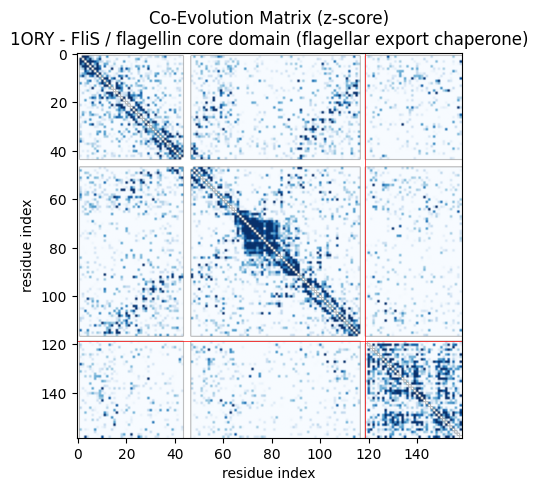

  -> precision=1.000  total_time=30.9s

[2/18] 3TUF - SpoIIIAH/IIQ Sporulation and germination complex
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['B'](158aa), Job_2=['A'](115aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 484614.62
iter 10 281287.59
iter 20 252620.92
iter 30 245847.84
iter 40 242546.79
iter 50 241274.47
iter 60 240859.13
iter 70 240692.31
iter 80 240612.0
iter 90 240566.93
iter 100 240536.56


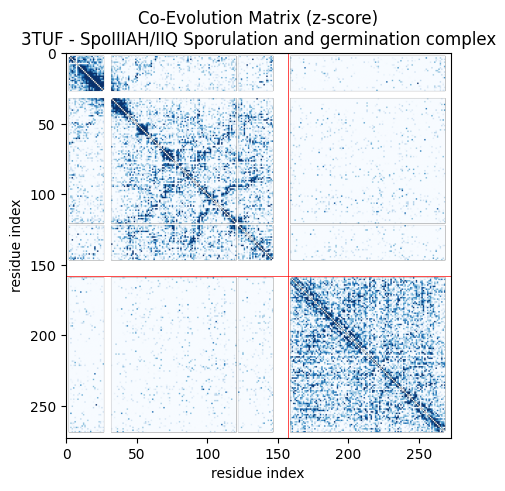

  -> precision=0.045  total_time=18.4s

[3/18] 1F80 - AcpS / ACP (fatty-acid synthesis, holo-ACP synthase)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B', 'C'](118aa), Job_2=['D', 'E', 'F'](74aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 479224.93
iter 10 330886.42
iter 20 278405.57
iter 30 259721.23
iter 40 253093.66
iter 50 250734.33
iter 60 249890.82
iter 70 249553.63
iter 80 249413.01
iter 90 249338.95
iter 100 249289.83


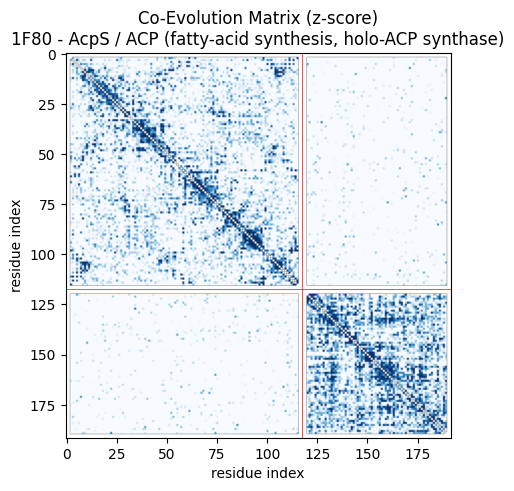

  -> precision=0.000  total_time=24.0s

[4/18] 3D3C - NusB / S10 (transcription antitermination)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B', 'C'](138aa), Job_2=['K', 'L', 'J'](87aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 546274.05
iter 10 404403.28
iter 20 340978.28
iter 30 314999.86
iter 40 303987.13
iter 50 299287.75
iter 60 297300.56
iter 70 296421.18
iter 80 296022.7
iter 90 295822.59
iter 100 295710.87


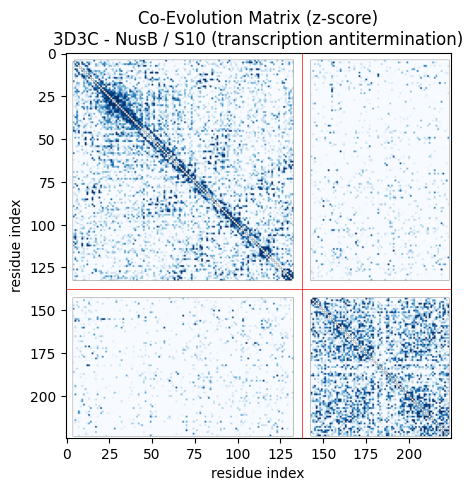

  -> precision=0.000  total_time=27.2s

[5/18] 1FFG - CheA (P2 domain) / CheY (chemotaxis)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'C'](128aa), Job_2=['B', 'D'](68aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:01 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 4387.8
iter 10 2862.6
iter 20 2731.8
iter 30 2654.9
iter 40 2627.64
iter 50 2617.48
iter 60 2614.18
iter 70 2613.08
iter 80 2612.72
iter 90 2612.59
iter 100 2612.55


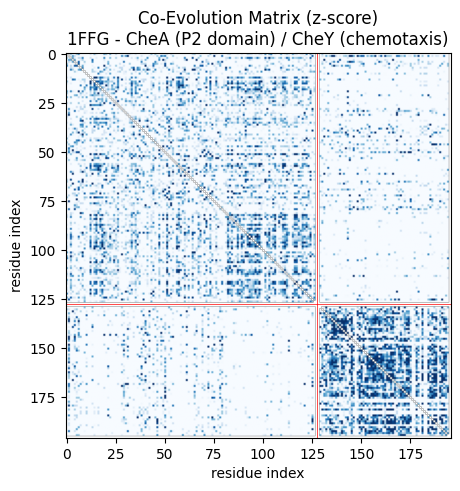

  -> precision=0.000  total_time=7.6s

[6/18] 1MG9 - ClpS / ClpA N-domain (AAA+ protease substrate adaptor)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['B'](143aa), Job_2=['A'](84aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 267447.28
iter 10 150033.29
iter 20 138778.89
iter 30 132822.51
iter 40 130732.18
iter 50 130111.95
iter 60 129845.73
iter 70 129746.82
iter 80 129702.08
iter 90 129680.47
iter 100 129668.04


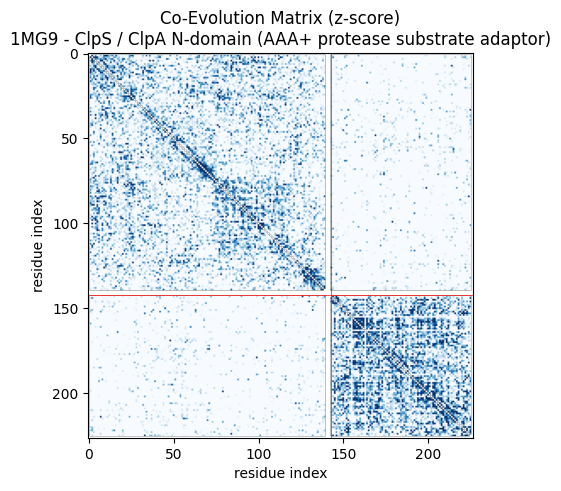

  -> precision=0.188  total_time=31.1s

[7/18] 1GGR - HPr / EIIA-Glc (PTS sugar-transport phosphorelay)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A'](150aa), Job_2=['B'](85aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 689777.69
iter 10 470062.95
iter 20 395203.11
iter 30 368592.68
iter 40 357998.21
iter 50 353912.62
iter 60 352354.39
iter 70 351730.53
iter 80 351465.39
iter 90 351343.85
iter 100 351274.11


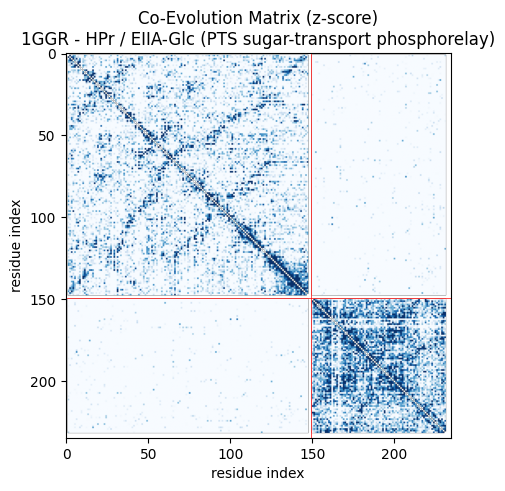

  -> precision=0.000  total_time=30.5s

[8/18] 1SC5 - FlgM / sigma28 (FliA) (flagellar anti-sigma factor)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A'](228aa), Job_2=['B'](72aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:01 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 1506.49
iter 10 1185.18
iter 20 1052.09
iter 30 1039.34
iter 40 1030.04
iter 50 1024.13
iter 60 1022.07
iter 70 1021.53
iter 80 1021.43
iter 90 1021.38
iter 100 1021.36


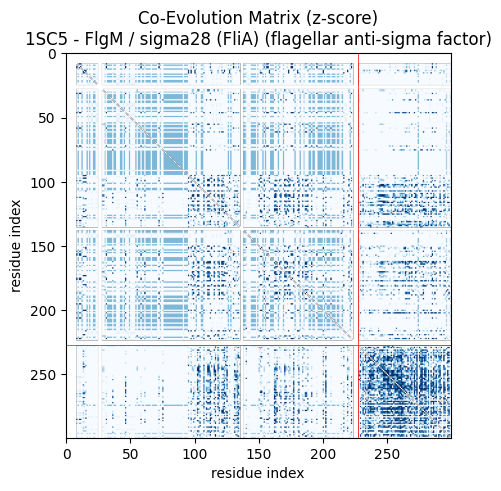

  -> precision=0.143  total_time=8.0s

[9/18] 1OR7 - RseA / sigmaE (envelope-stress anti-sigma factor)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B'](184aa), Job_2=['C', 'F'](66aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 427977.71
iter 10 261325.72
iter 20 227096.39
iter 30 219150.24
iter 40 216050.67
iter 50 214735.5
iter 60 214243.86
iter 70 214043.26
iter 80 213937.41
iter 90 213875.39
iter 100 213832.31


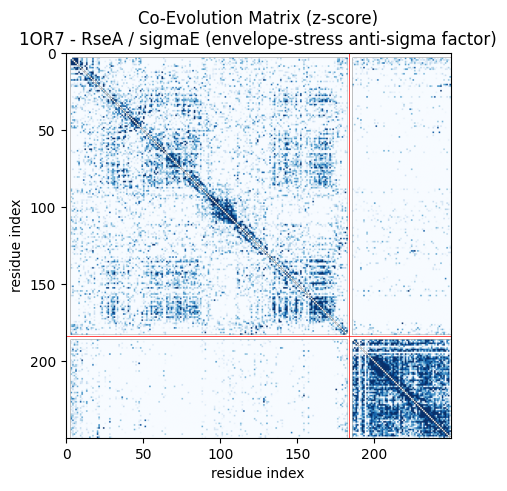

  -> precision=0.846  total_time=31.9s

[10/18] 3DGE - RR468 / HK853 (two-component signal transduction)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B'](237aa), Job_2=['C', 'D'](122aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:05 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 1366124.7
iter 10 1005379.25
iter 20 844885.98
iter 30 772803.63
iter 40 740206.33
iter 50 725467.07
iter 60 718752.27
iter 70 715609.01
iter 80 714109.69
iter 90 713363.53
iter 100 712976.37


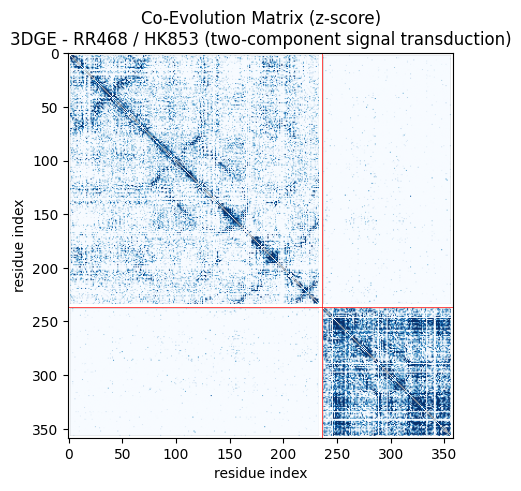

  -> precision=0.000  total_time=88.5s

[11/18] 2WUS - RodZ / MreB (cell-shape-determining cytoskeleton)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B'](335aa), Job_2=['R', 'S'](87aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:02 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 437237.27
iter 10 257888.65
iter 20 226579.18
iter 30 216112.5
iter 40 211772.12
iter 50 210376.21
iter 60 209808.68
iter 70 209554.72
iter 80 209429.58
iter 90 209355.8
iter 100 209307.96


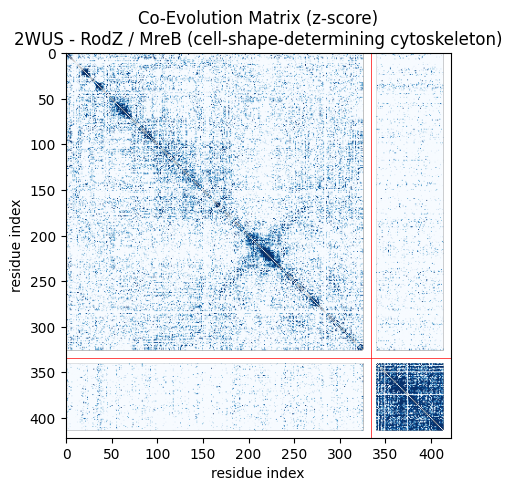

  -> precision=0.000  total_time=74.6s

[12/18] 3LVL - IscU / IscS (Fe-S cluster biogenesis)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['B'](388aa), Job_2=['A'](125aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:04 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 1032251.26
iter 10 625101.56
iter 20 537422.38
iter 30 516436.75
iter 40 510364.0
iter 50 507627.54
iter 60 506421.86
iter 70 505911.56
iter 80 505636.07
iter 90 505446.08
iter 100 505296.55


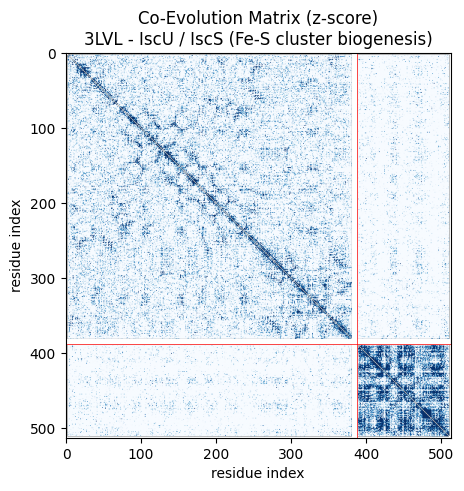

  -> precision=0.040  total_time=119.9s

[13/18] 1DKG - GrpE / DnaK ATPase domain (Hsp70 chaperone system)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['D'](376aa), Job_2=['A', 'B'](158aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:08 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 551766.38
iter 10 374576.35
iter 20 320568.02
iter 30 307563.34
iter 40 303136.61
iter 50 301367.34
iter 60 300541.72
iter 70 300115.88
iter 80 299853.54
iter 90 299653.38
iter 100 299486.63


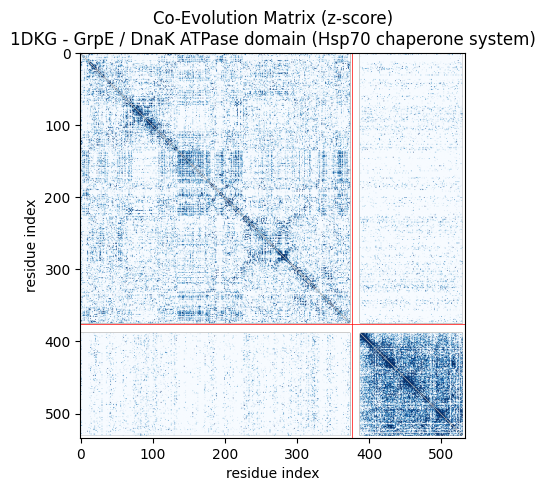

  -> precision=0.065  total_time=137.0s

[14/18] 1JQJ - delta subunit / beta clamp (DNA polymerase III clamp loader)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B'](366aa), Job_2=['C', 'D'](328aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:03 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 2098790.96
iter 10 1135712.92
iter 20 990356.29
iter 30 957521.36
iter 40 939663.67
iter 50 933169.81
iter 60 931277.52
iter 70 930409.37
iter 80 930015.81
iter 90 929811.91
iter 100 929676.0


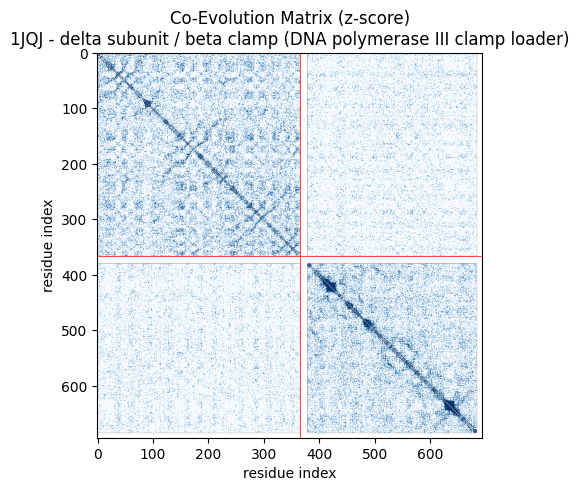

  -> precision=0.015  total_time=155.2s

[15/18] 8TJ3 - RodA / PBP2 (elongasome peptidoglycan synthase, E. coli)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['C'](492aa), Job_2=['B'](341aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:05 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 2849278.21
iter 10 1657657.69
iter 20 1404492.94
iter 30 1347645.57
iter 40 1331140.83
iter 50 1323945.42
iter 60 1321011.76
iter 70 1319948.67
iter 80 1319521.65
iter 90 1319285.82
iter 100 1319125.42


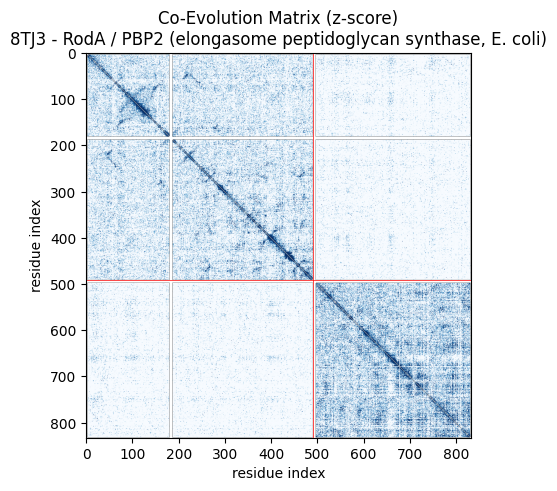

  -> precision=0.221  total_time=263.0s

[16/18] 5LP5 - MreC / PBP2 (elongasome core, H. pylori)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A', 'B'](535aa), Job_2=['C', 'D', 'E', 'F'](157aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 03:23 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 2135081.85
iter 10 1235538.28
iter 20 1052327.71
iter 30 1012227.97
iter 40 999681.74
iter 50 993973.0
iter 60 991657.48
iter 70 990807.65
iter 80 990415.78
iter 90 990177.25
iter 100 990005.51


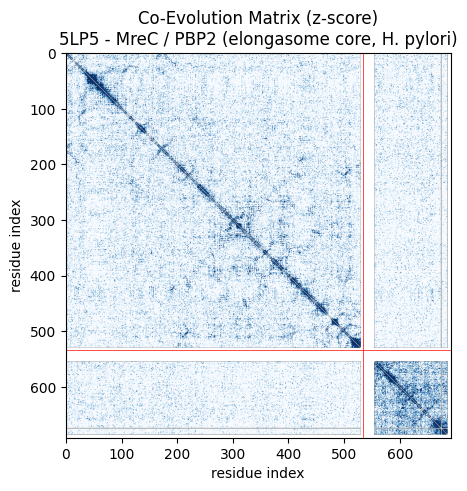

  -> precision=0.161  total_time=360.6s

[17/18] 1PDK - PapD / PapK (chaperone-usher pilus biogenesis, donor-strand complementation)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['A'](215aa), Job_2=['B'](149aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 00:43 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 1096675.94
iter 10 667188.61
iter 20 561129.93
iter 30 535862.41
iter 40 528216.38
iter 50 525399.46
iter 60 524295.72
iter 70 523853.71
iter 80 523662.57
iter 90 523556.42
iter 100 523482.03


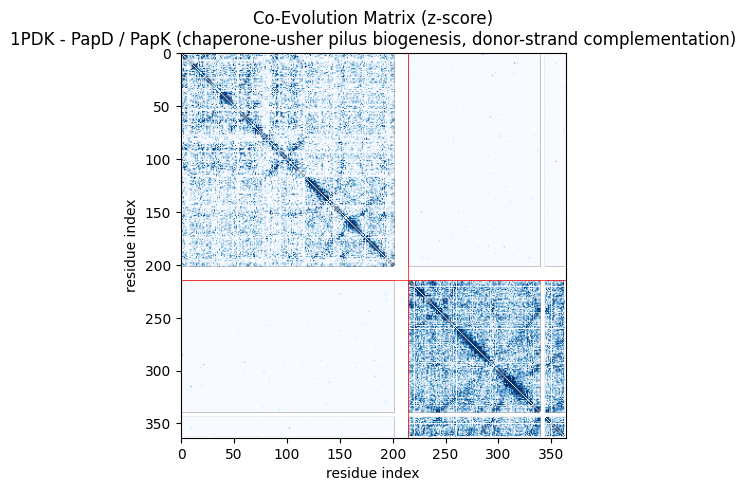

  -> precision=nan  total_time=80.4s

[18/18] 1RJ9 - Ffh / FtsY (SRP + SRP receptor, cotranslational targeting GTPases)
    parse_structure_chains: position/identity fallback -> 2 job(s): Job_1=['B'](282aa), Job_2=['A'](277aa)
getting paired MSA


COMPLETE: 100%|██████████| 300/300 [elapsed: 02:11 remaining: 00:00]


parsing msas
gathering info
filtering sequences
selecting final sequences
starting 869958.23
iter 10 537291.83
iter 20 457271.46
iter 30 436859.38
iter 40 430920.41
iter 50 428537.28
iter 60 427459.53
iter 70 427007.13
iter 80 426768.11
iter 90 426603.14
iter 100 426470.67


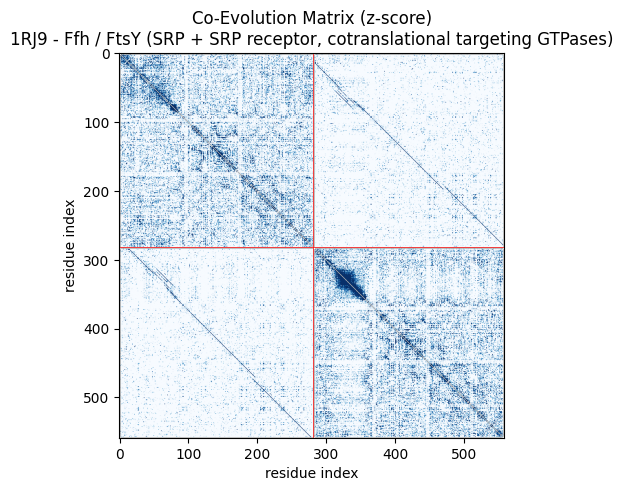

  -> precision=0.036  total_time=287.4s


,pdb_id,label,n_chains,chain_lengths,total_length,msa_time_sec,neff,depth_ratio,gremlin_time_sec,peak_ram_mb,...,peak_gpu_mem_mb,L_struct,n_interchain_total,requested_top_n,n_candidates_after_filter,top_n_used,n_hits,precision,total_time_sec,status
0,1ORY,FliS / flagellin core domain (flagellar export...,2,119;40,159,8.976340,1586.010390,9.974908,8.932016,1490.085938,...,1143.0,159,4520,8,43,8,8,1.000000,30.861851,ok
1,3TUF,SpoIIIAH/IIQ Sporulation and germination complex,2,158;115,273,3.021123,1301.817242,4.768561,10.528661,1758.464844,...,1143.0,273,15290,23,22,22,1,0.045455,18.354090,ok
2,1F80,"AcpS / ACP (fatty-acid synthesis, holo-ACP syn...",2,118;74,192,5.105489,1777.376322,9.257168,9.251662,1717.132812,...,1143.0,192,7980,14,3,3,0,0.000000,23.962429,ok
3,3D3C,NusB / S10 (transcription antitermination),2,138;87,225,4.441587,1891.841986,8.408187,11.617943,1738.152344,...,1143.0,225,10449,17,73,17,0,0.000000,27.247438,ok
4,1FFG,CheA (P2 domain) / CheY (chemotaxis),2,128;68,196,1.402199,21.000000,0.107143,3.609402,1679.078125,...,1143.0,196,8382,13,140,13,0,0.000000,7.624190,ok
5,1MG9,ClpS / ClpA N-domain (AAA+ protease substrate ...,2,143;84,227,7.992403,755.264456,3.327156,12.931834,1724.542969,...,1143.0,227,11537,16,38,16,3,0.187500,31.118211,ok
6,1GGR,HPr / EIIA-Glc (PTS sugar-transport phosphorelay),2,150;85,235,5.004787,2072.038132,8.817184,14.157437,1872.117188,...,1143.0,235,12054,17,3,3,0,0.000000,30.541655,ok
7,1SC5,FlgM / sigma28 (FliA) (flagellar anti-sigma fa...,2,228;72,300,1.400322,7.700000,0.025667,5.445267,2035.500000,...,2167.0,300,15192,14,675,14,2,0.142857,8.028876,ok
8,1OR7,RseA / sigmaE (envelope-stress anti-sigma factor),2,184;66,250,3.662359,1136.637974,4.546552,16.485888,1904.726562,...,2167.0,250,11520,13,34,13,11,0.846154,31.943819,ok
9,3DGE,RR468 / HK853 (two-component signal transduction),2,237;122,359,40.551563,2522.186261,7.025588,32.305193,2388.691406,...,2167.0,359,27608,24,1,1,0,0.000000,88.510473,ok


In [ ]:
#@title Run the 20-complex GREMLIN benchmark
COMPLEXES = [
    ("1ORY", "FliS / flagellin core domain (flagellar export chaperone)"),
    ("3TUF", "SpoIIIAH/IIQ Sporulation and germination complex"),
    ("1F80", "AcpS / ACP (fatty-acid synthesis, holo-ACP synthase)"),
    ("3D3C", "NusB / S10 (transcription antitermination)"),
    ("1FFG", "CheA (P2 domain) / CheY (chemotaxis)"),
    ("1MG9", "ClpS / ClpA N-domain (AAA+ protease substrate adaptor)"),
    ("1GGR", "HPr / EIIA-Glc (PTS sugar-transport phosphorelay)"),
    ("1SC5", "FlgM / sigma28 (FliA) (flagellar anti-sigma factor)"),
    ("1OR7", "RseA / sigmaE (envelope-stress anti-sigma factor)"),
    ("3DGE", "RR468 / HK853 (two-component signal transduction)"),
    ("2WUS", "RodZ / MreB (cell-shape-determining cytoskeleton)"),
    ("3LVL", "IscU / IscS (Fe-S cluster biogenesis)"),
    ("1DKG", "GrpE / DnaK ATPase domain (Hsp70 chaperone system)"),
    ("1JQJ", "delta subunit / beta clamp (DNA polymerase III clamp loader)"),
    ("8TJ3", "RodA / PBP2 (elongasome peptidoglycan synthase, E. coli)"),
    ("5LP5", "MreC / PBP2 (elongasome core, H. pylori)"),
    ("1PDK", "PapD / PapK (chaperone-usher pilus biogenesis, donor-strand complementation)"),  # 375 aa combined
    ("1RJ9", "Ffh / FtsY (SRP + SRP receptor, cotranslational targeting GTPases)"),
]
# Sorted smallest combined sequence length first (~174 aa) to ~815 aa. Every entry here
# is a genuine 1-vs-1 bacterial complex - exactly 2 distinct interacting proteins, no
# toxin-antitoxin systems, no 3+-chain assemblies - confirmed on RCSB before being put
# in this list. 8TJ3 and 5LP5 run past the ~600 aa soft cap (both real elongasome
# machinery, named explicitly as test cases), everything else sits comfortably under it.

opt_iter_final = 100          #@param {type:"integer"}
contact_dist = 18.0           #@param {type:"number"}
use_zscore_filter = True      #@param {type:"boolean"}
zscore_threshold = 1          #@param {type:"number"}

results = []
candidate_pools = {}  # pdb_id -> candidate pool, kept for the pooled z-score sweep at the end
for rank, (pdb_id, label) in enumerate(COMPLEXES, 1):
    print(f"\n{'='*70}\n[{rank}/{len(COMPLEXES)}] {pdb_id} - {label}\n{'='*70}")
    row = {"pdb_id": pdb_id, "label": label}
    t_total0 = time.time()
    try:
        np.random.seed(rank)  # same split/seed used by the CCMpred notebook for a fair comparison

        struct_file = get_pdb_file(pdb_id)
        structure, query_sequence, job_info, chain_pos_map = parse_structure_chains(struct_file)
        row["n_chains"] = len(job_info)
        row["chain_lengths"] = ";".join(str(j["sequence_length"]) for j in job_info)
        row["total_length"] = sum(j["sequence_length"] for j in job_info)
        if len(job_info) < 2:
            raise ValueError(f"only {len(job_info)} unique chain(s) found - not a heteromer, skipping")

        jobname = f"job_{pdb_id}"

        t0 = time.time()
        run_prep_inputs(query_sequence, jobname)
        row["msa_time_sec"] = time.time() - t0

        names, seqs = parse_a3m(f"{jobname}/msa.a3m")
        train_seqs, test_seqs = split_train_test(seqs, frac_test=0.1)
        msa = mk_msa(train_seqs, gap_cutoff=0.5, eff_cutoff=0.8)
        row["neff"] = float(msa["neff"])
        row["depth_ratio"] = float(msa["neff"] / len(seqs[0]))

        mon = ResourceMonitor()
        mon.start()
        t0 = time.time()
        mrf = GREMLIN(msa, lam_w=0.01, opt_iter=opt_iter_final)
        row["gremlin_time_sec"] = time.time() - t0
        mon.stop()
        row["peak_ram_mb"] = mon.peak_ram_mb
        row["peak_cpu_pct"] = mon.peak_cpu_pct
        row["peak_gpu_pct"] = mon.peak_gpu_pct
        row["peak_gpu_mem_mb"] = mon.peak_gpu_mem_mb

        mtx = get_mtx(mrf)
        plot_coev_mtx(mtx, pdb_id, label, job_info)

        pool = interchain_candidate_pool(structure, job_info, mtx, chain_pos_map, contact_dist=contact_dist)
        candidate_pools[pdb_id] = pool
        row["L_struct"] = pool["L_struct"]
        row["n_interchain_total"] = pool["n_interchain_total"]
        row["requested_top_n"] = pool["requested_top_n"]
        thresh = zscore_threshold if use_zscore_filter else -np.inf
        row.update(precision_at_threshold(pool, thresh))

        row["total_time_sec"] = time.time() - t_total0
        row["status"] = "ok"
        print(f"  -> precision={row.get('precision', float('nan')):.3f}  total_time={row['total_time_sec']:.1f}s")

    except Exception as e:
        row["status"] = f"FAILED: {type(e).__name__}: {e}"
        row["total_time_sec"] = time.time() - t_total0
        print(f"  -> FAILED: {e}")

    results.append(row)
    gc.collect()

results_df = pd.DataFrame(results)
results_df.to_csv("gremlin_publication_results.csv", index=False)
display(results_df)


18/18 complexes completed successfully
Mean intermolecular Top-L/5 precision: 0.162  (std 0.297)
Mean total runtime per complex: 98.7s (MSA: 38.1s, GREMLIN fit: 44.1s)
Mean peak RAM: 3958 MB   Mean peak GPU mem: 5511 MB


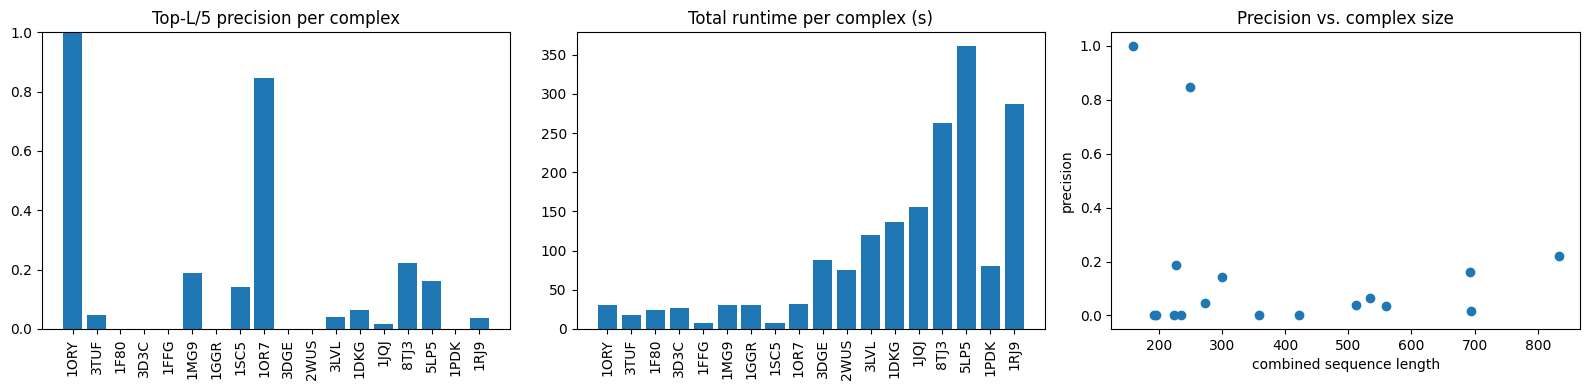

In [ ]:
#@title Summary: precision & runtime across the 20-complex panel
ok = results_df[results_df["status"] == "ok"].copy()
print(f"{len(ok)}/{len(results_df)} complexes completed successfully")
if len(ok):
    print(f"Mean intermolecular Top-L/5 precision: {ok['precision'].mean():.3f}  (std {ok['precision'].std():.3f})")
    print(f"Mean total runtime per complex: {ok['total_time_sec'].mean():.1f}s "
          f"(MSA: {ok['msa_time_sec'].mean():.1f}s, GREMLIN fit: {ok['gremlin_time_sec'].mean():.1f}s)")
    print(f"Mean peak RAM: {ok['peak_ram_mb'].mean():.0f} MB   Mean peak GPU mem: {ok['peak_gpu_mem_mb'].mean():.0f} MB")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].bar(ok["pdb_id"], ok["precision"])
    axes[0].set_title("Top-L/5 precision per complex")
    axes[0].set_ylim(0, 1)
    axes[0].tick_params(axis="x", rotation=90)

    axes[1].bar(ok["pdb_id"], ok["total_time_sec"])
    axes[1].set_title("Total runtime per complex (s)")
    axes[1].tick_params(axis="x", rotation=90)

    axes[2].scatter(ok["total_length"], ok["precision"])
    axes[2].set_xlabel("combined sequence length")
    axes[2].set_ylabel("precision")
    axes[2].set_title("Precision vs. complex size")

    plt.tight_layout()
    plt.savefig("gremlin_publication_summary.png", dpi=150)
    plt.show()

if (results_df["status"] != "ok").any():
    print("\nFailed complexes:")
    display(results_df[results_df["status"] != "ok"][["pdb_id", "label", "status"]])


,zscore_threshold,pooled_precision,total_top_n,total_candidates
0,0.00,0.112500,480,212698
1,0.25,0.112500,480,141148
2,0.50,0.112500,480,88769
3,0.75,0.112500,480,52887
4,1.00,0.116883,462,29584
5,1.25,0.122172,442,15425
6,1.50,0.126866,402,7386
7,1.75,0.136364,374,3370
8,2.00,0.125749,334,1502
9,2.25,0.134615,260,709


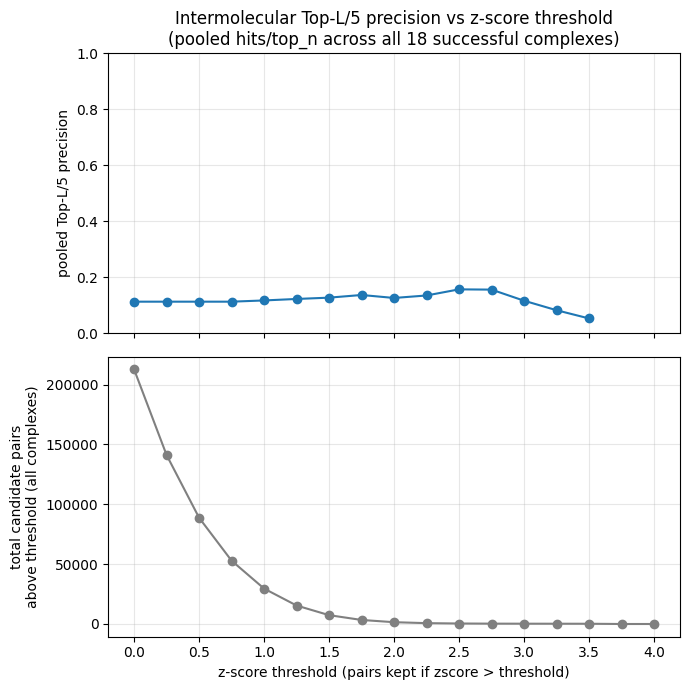

In [ ]:
#@title Z-score threshold sweep, pooled across all successful complexes
z_min = 0.0    #@param {type:"number"}
z_max = 4.0    #@param {type:"number"}
z_step = 0.25  #@param {type:"number"}

thresholds = np.arange(z_min, z_max + z_step / 2, z_step)
sweep_rows = []
for z in thresholds:
    total_hits = total_top_n = total_candidates = 0
    for pdb_id, pool in candidate_pools.items():
        r = precision_at_threshold(pool, z)
        total_hits += r["n_hits"]
        total_top_n += r["top_n_used"]
        total_candidates += r["n_candidates_after_filter"]
    pooled_precision = total_hits / total_top_n if total_top_n else float("nan")
    sweep_rows.append({"zscore_threshold": z, "pooled_precision": pooled_precision,
                        "total_top_n": total_top_n, "total_candidates": total_candidates})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv("zscore_sweep_pooled.csv", index=False)
display(sweep_df)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
ax1.plot(sweep_df["zscore_threshold"], sweep_df["pooled_precision"], marker="o")
ax1.set_ylabel("pooled Top-L/5 precision")
ax1.set_ylim(0, 1)
ax1.set_title(f"Intermolecular Top-L/5 precision vs z-score threshold\n"
              f"(pooled hits/top_n across all {len(candidate_pools)} successful complexes)")
ax1.grid(True, alpha=0.3)

ax2.plot(sweep_df["zscore_threshold"], sweep_df["total_candidates"], marker="o", color="gray")
ax2.set_xlabel("z-score threshold (pairs kept if zscore > threshold)")
ax2.set_ylabel("total candidate pairs\nabove threshold (all complexes)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("zscore_sweep_pooled.png", dpi=150)
plt.show()


In [ ]:
#@title Download the results CSVs
try:
    from google.colab import files
    files.download("gremlin_publication_results.csv")
    files.download("zscore_sweep_pooled.csv")
except Exception as e:
    print("not running in Colab, or download blocked:", e)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>